# Feature-space view of predicted classes (t-SNE)

Collects the image features each method actually classified with and shows a t-SNE of the samples tied to chosen classes.
- **NoAdapt features** are the zero-shot CLIP features.
- **Ramen features** are the features *after* Ramen's per-sample adaptation, i.e. the ones its prediction came from.

Showing both side by side reveals whether wrong predictions (e.g. frog/bird → *deer*) come from features that were already mixed up, or from features that adaptation moved into the deer region.

Everything you'd want to change is in the **Settings** cell.

In [1]:
%load_ext autoreload
%autoreload 2

import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '1')  # pick a free GPU; must be set before torch is imported

from ramen_analysis import make_experiment

/home/priyank1/miniconda3/envs/RAMEN/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Settings

In [2]:
# --- experiment (must match a run you want to analyse; results are cached in results/) ---
DATASET      = 'CIFAR10C'    # 'CIFAR10C' | 'CIFAR100C'
MODEL        = None          # None = dataset default (CIFAR10C: clip_vitbase32, CIFAR100C: clip_vitbase16)
TTA_MODE     = 'mixed'       # 'mixed' | 'single'
N_PER_DOMAIN = None          # None = whole dataset; e.g. 1000 for a quick run

# --- what to plot ---
CLASSES       = ['deer']     # one or more class names (CIFAR-100 e.g. ['shark', 'pickup_truck'])
SELECT        = 'pred'       # 'pred' predicted as CLASSES | 'true' labelled CLASSES | 'either' | 'wrong' (wrongly predicted as CLASSES)
SELECT_BY     = 'Ramen'      # whose predictions define the selection: 'Ramen' | 'NoAdapt'
COLOR_BY      = 'label'      # 'label' (true class) | 'pred' | 'domain' | 'outcome' (fixed/broken vs NoAdapt) | 'correct'
FEATURES_FROM = None         # None = both side by side | 'Ramen' | 'NoAdapt'
DOMAINS       = None         # None = all corruptions, or e.g. ['gaussian_noise', 'shot_noise']
MAX_POINTS    = 3000         # random subsample above this (t-SNE gets slow past ~10k points)
PERPLEXITY    = 30

## Run (or load) both methods with feature capture
This re-runs a method if its cached results were saved without features (e.g. by the other notebooks), so expect roughly the same time as a normal evaluation the first time.

In [3]:
exp = make_experiment(DATASET, model=MODEL, tta_mode=TTA_MODE, n_per_domain=N_PER_DOMAIN).load()
exp.evaluate(capture_features=True)

CIFAR10C: 15 corruptions x 10000 images, 10 classes, model=clip_vitbase32, mode=mixed
NoAdapt: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/CIFAR10C_clip_vitbase32_mixed_nall_bs100_s0_NoAdapt.pkl
Ramen: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/CIFAR10C_clip_vitbase32_mixed_nall_bs100_s0_Ramen.pkl


,NoAdapt,Ramen,delta
gaussian_noise,38.66,60.84,22.18
shot_noise,42.59,63.14,20.55
impulse_noise,42.75,56.27,13.52
defocus_blur,72.61,77.12,4.51
glass_blur,43.91,64.01,20.10
motion_blur,66.68,77.55,10.87
zoom_blur,71.69,79.27,7.58
snow,73.78,80.65,6.87
frost,75.69,80.16,4.47
fog,68.85,77.93,9.08


## What gets absorbed into the class?
True labels of all samples each method predicts as `CLASSES[0]`.

In [4]:
exp.pred_composition(CLASSES[0])

,NoAdapt,Ramen
label,,
deer,6996,11390
frog,618,2379
bird,609,1905
cat,469,1217
horse,830,1087
dog,403,900
airplane,95,172
ship,62,64
truck,174,24


## t-SNE
Colour is set by `COLOR_BY`; marker shows whether `SELECT_BY` got the sample right (o) or wrong (x). Each panel is a separate t-SNE run on the same samples, so compare which points sit together, not absolute positions.

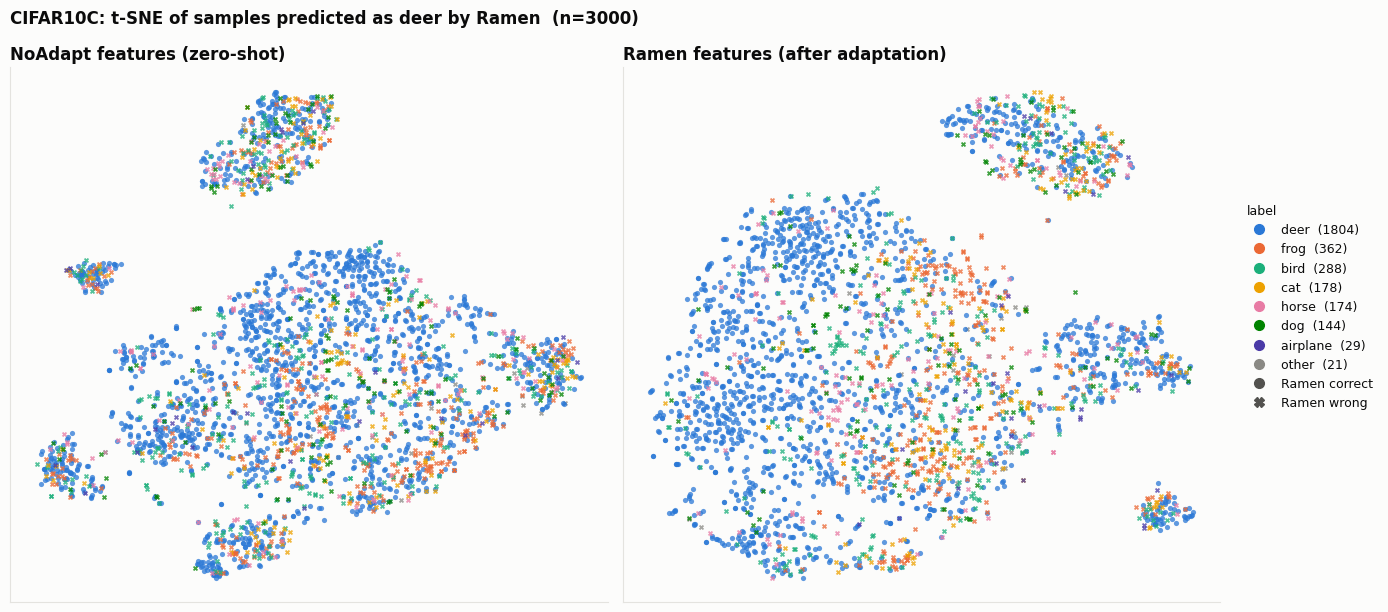

In [5]:
fig, panels = exp.plot_tsne(CLASSES, select=SELECT, algo=SELECT_BY, features_from=FEATURES_FROM, color_by=COLOR_BY,
                            domains=DOMAINS, max_points=MAX_POINTS, perplexity=PERPLEXITY)

## Variations
Only the errors (samples wrongly pulled into the class), coloured by corruption: do certain corruptions drive the collapse?

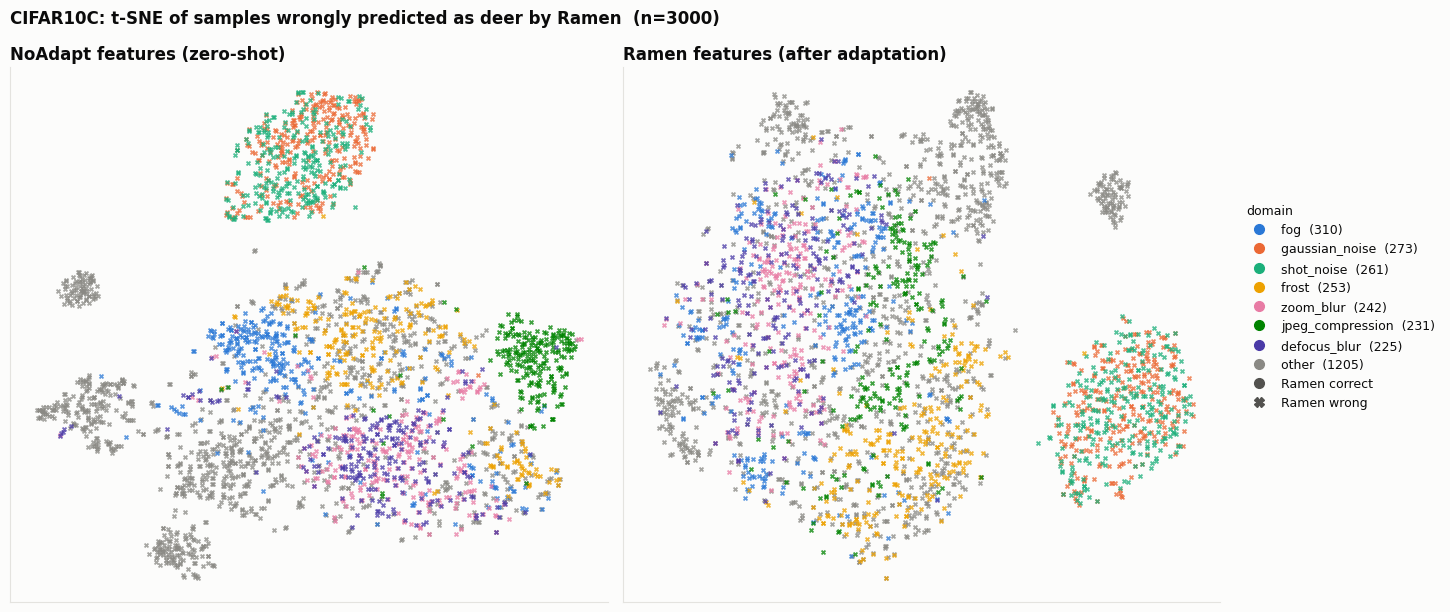

In [6]:
exp.plot_tsne(CLASSES, select='wrong', color_by='domain');

Coloured by flip outcome vs NoAdapt. Red = Ramen broke a correct zero-shot prediction.

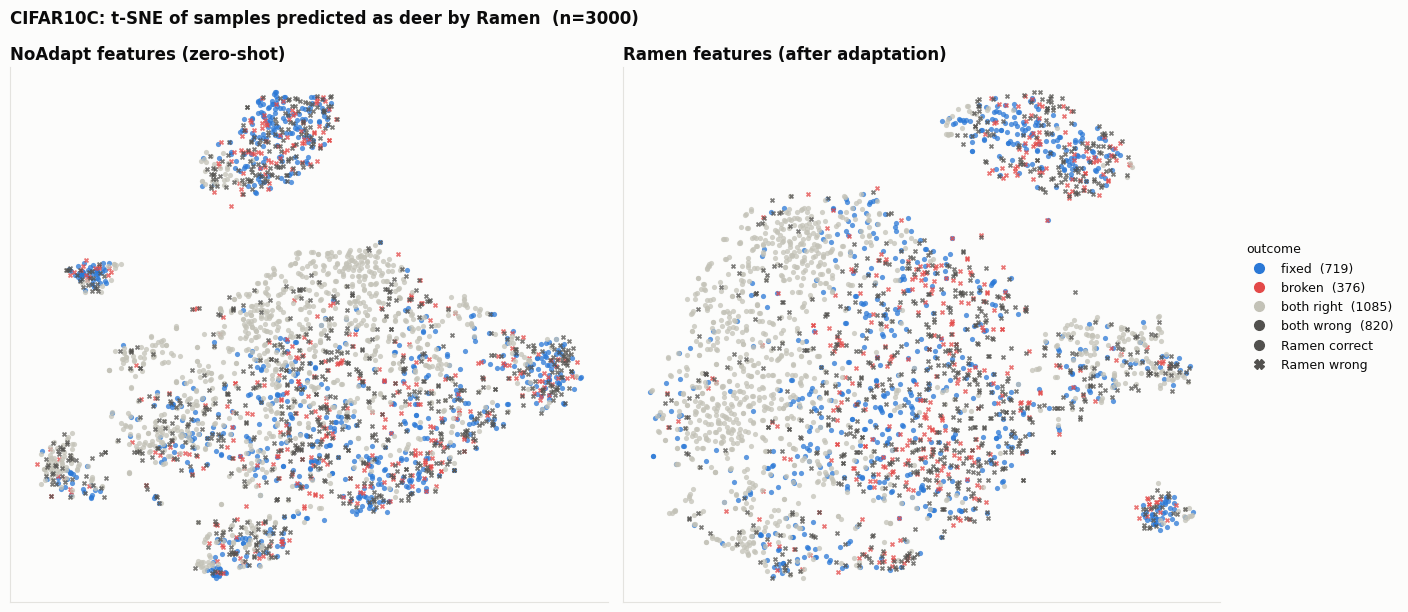

In [7]:
exp.plot_tsne(CLASSES, select='pred', color_by='outcome');

The reverse view: where do samples *truly* of the class end up, coloured by what Ramen predicted?

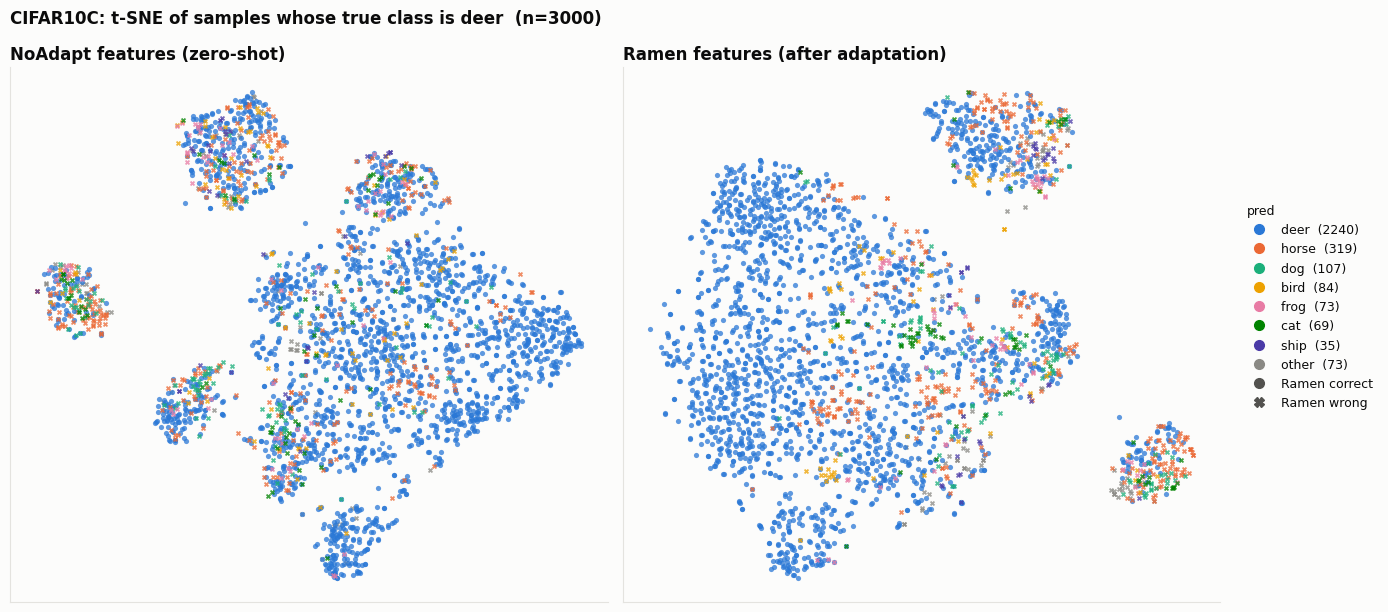

In [8]:
exp.plot_tsne(CLASSES, select='true', color_by='pred');

Loop over several classes, e.g. the ones Ramen over-predicts most (see `plot_prediction_bias` in the dataset notebooks).

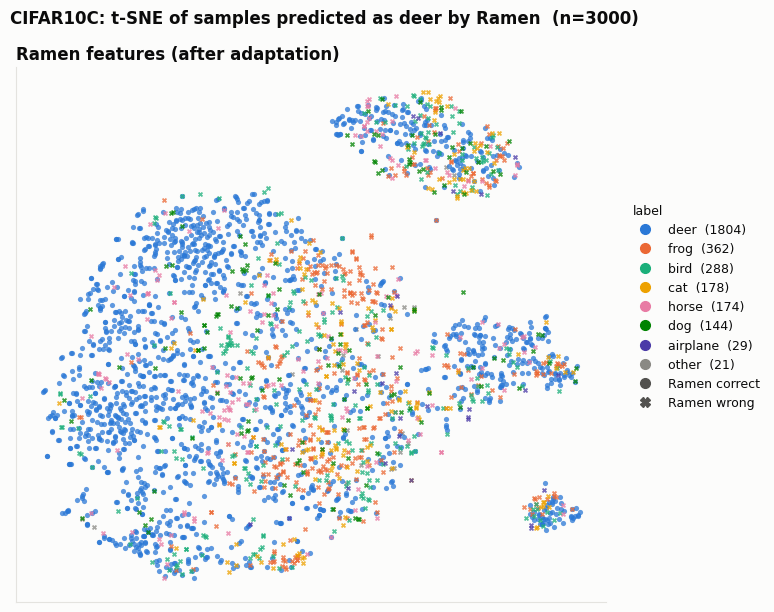

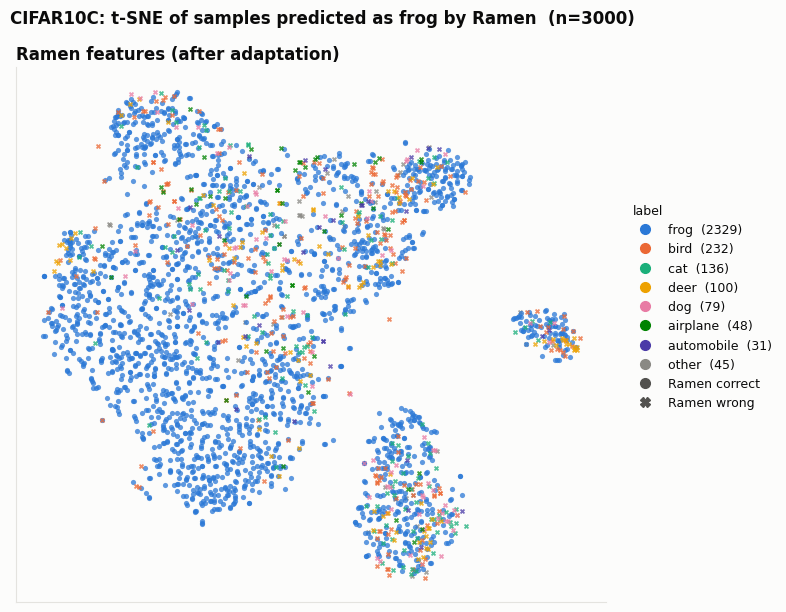

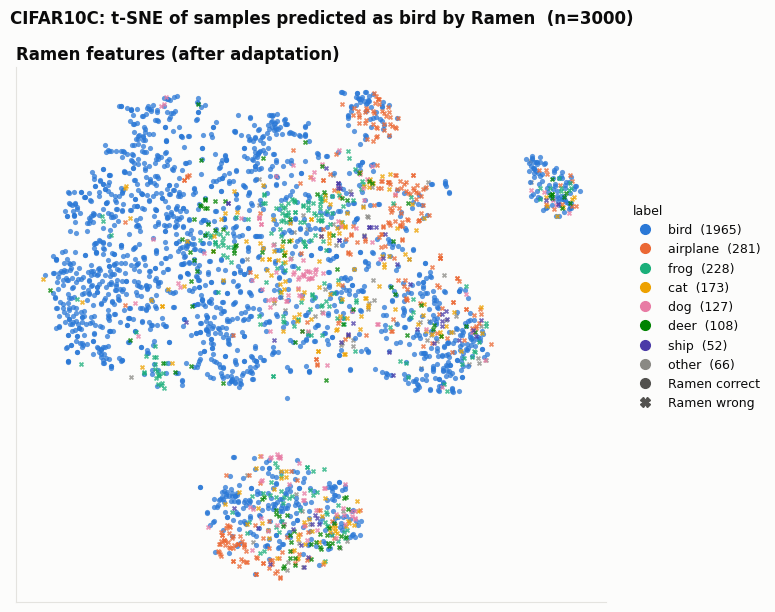

In [9]:
for cls in ['deer', 'frog', 'bird']:   # change to any classes of DATASET
    exp.plot_tsne(cls, select='pred', color_by='label', features_from='Ramen')

## Use the coordinates yourself
`plot_tsne` returns one DataFrame per panel with t-SNE `x`, `y` and every per-sample column (true/pred names, domain, confidence, outcome, ...).

In [10]:
panels[-1][['x', 'y', 'true_name', 'pred_name', 'domain', 'conf', 'outcome']].head()

,x,y,true_name,pred_name,domain,conf,outcome
132481,-28.241631,-33.529831,dog,deer,elastic_transform,0.994743,both wrong
61894,34.903774,-0.811906,deer,deer,glass_blur,0.920988,both right
147564,-30.799566,20.443064,horse,deer,fog,0.998602,both wrong
94740,-37.699467,-16.711960,deer,deer,defocus_blur,0.997360,both right
129778,1.938763,-2.055063,deer,deer,jpeg_compression,0.758045,fixed
